# 03 · Signal Processing

**Input:** the clean layer built in notebook 02 (`clean.trip_signals`, `clean.trips`).

**Goal:** turn raw 10 Hz signals into engineering quantities that the later steps (EDA, models, anomalies, dashboard)
can use directly:

| Section | Output table (DuckDB schema `signal`) |
|---|---|
| 1 Smoothing | `signal.samples`: smoothed voltage, current and power for every sample |
| 2 Phase segments | `signal.segments`: one row per continuous driving / stopped / charging stretch |
| 3 Voltage-sag events | `signal.sag_events`: one row per heavy-load voltage dip, with apparent pack resistance |
| 4 Temperature rise | `signal.temp_rise`: battery temperature rise and rate per trip |
| 5 Per-trip energy | `signal.trip_energy`: energy used, recovered, charged, heating, distance, consumption |

Nothing beyond signal processing happens here: no EDA conclusions, no models.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import savgol_filter

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = ROOT / "data" / "warehouse" / "volvo.duckdb"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
HZ = 10
DT = 1 / HZ

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

con = duckdb.connect(str(DB_PATH))
s = con.sql("""
    SELECT trip_id, series, row_idx, time_s, phase, speed_kmh, batt_voltage_v, batt_current_a, soc_pct, soc_gap,
           batt_temp_c, ambient_temp_c, heating_power_can_kw, aircon_power_kw
    FROM clean.trip_signals ORDER BY trip_id, row_idx
""").df()
trips = con.sql("SELECT * FROM clean.trips ORDER BY trip_id").df()
print(f"{len(s):,} samples, {s.trip_id.nunique()} trips")

1,094,793 samples, 70 trips


## 1 · Smoothing

Battery voltage and current carry sample-to-sample noise (measured below). Two smoothers are compared over a
**2-second window** (21 samples):
- **moving average:** simple, but flattens the short peaks that matter for voltage sag
- **Savitzky-Golay** (2nd-order polynomial): removes the noise while keeping the height and timing of peaks

Smoothing is applied per trip, so no window ever crosses from one trip into the next.

In [2]:
WINDOW = 2 * HZ + 1  # 21 samples = 2 s


def per_trip(col, fn):
    return s.groupby("trip_id", sort=False)[col].transform(fn)


def moving_average(x):
    return x.rolling(WINDOW, center=True, min_periods=1).mean()


def savgol(x):
    return pd.Series(savgol_filter(x.to_numpy(), WINDOW, 2), index=x.index) if len(x) >= WINDOW else x


s["power_kw"] = s.batt_voltage_v * s.batt_current_a / 1000  # negative = discharge, same sign as current
SMOOTHED = {"batt_voltage_v": "voltage_smooth_v", "batt_current_a": "current_smooth_a", "power_kw": "power_smooth_kw"}


def step_noise(x):
    # standard deviation of sample-to-sample changes, never across trip boundaries
    return x.groupby(s.trip_id).diff().std()


comparison = []
for col, out in SMOOTHED.items():
    ma, sg = per_trip(col, moving_average), per_trip(col, savgol)
    raw_noise = step_noise(s[col])
    for name, sm in [("moving average", ma), ("Savitzky-Golay", sg)]:
        # how much of each trip's deepest point survives: 1.0 = peak fully kept
        peak_kept = (sm.groupby(s.trip_id).min() / s.groupby("trip_id")[col].min()).median()
        comparison.append(dict(signal=col, smoother=name,
                               noise_removed_pct=round(100 * (1 - step_noise(sm) / raw_noise), 1),
                               trip_minimum_kept=round(peak_kept, 3)))
    s[out] = sg
comparison = pd.DataFrame(comparison)
comparison

,signal,smoother,noise_removed_pct,trip_minimum_kept
0,batt_voltage_v,moving average,38.9,1.002
1,batt_voltage_v,Savitzky-Golay,15.5,1.000
2,batt_current_a,moving average,42.3,0.956
3,batt_current_a,Savitzky-Golay,17.4,0.999
4,power_kw,moving average,42.7,0.960
5,power_kw,Savitzky-Golay,17.7,1.000


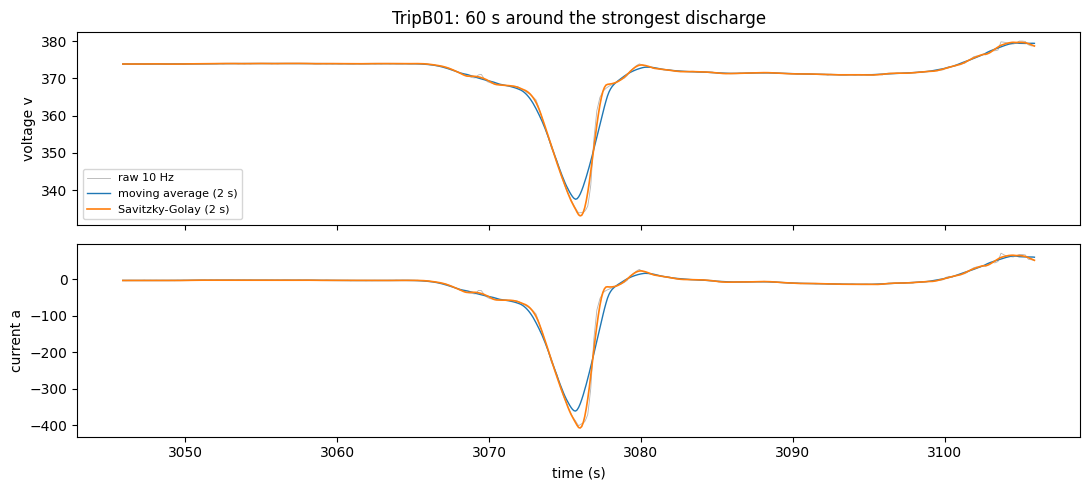

In [3]:
# zoom on 60 s of heavy driving to show what each smoother does
t = "TripB01"
g = s[s.trip_id == t]
peak = g.batt_current_a.idxmin()
w = g.loc[peak - 300:peak + 300]
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for ax, col, sm in [(axes[0], "batt_voltage_v", "voltage_smooth_v"), (axes[1], "batt_current_a", "current_smooth_a")]:
    ax.plot(w.time_s, w[col], lw=0.6, color="0.7", label="raw 10 Hz")
    ax.plot(w.time_s, moving_average(w[col]), lw=1, label="moving average (2 s)")
    ax.plot(w.time_s, w[sm], lw=1.2, label="Savitzky-Golay (2 s)")
    ax.set_ylabel(col.replace("batt_", "").replace("_", " "))
axes[0].legend(fontsize=8)
axes[0].set_title(f"{t}: 60 s around the strongest discharge")
axes[1].set_xlabel("time (s)")
fig.tight_layout()
fig.savefig(FIGURES / "03_smoothing.png", dpi=150)
plt.show()

## 2 · Phase segments

Notebook 02 labelled every sample. Here consecutive samples with the same label become **segments**.
At the 1 km/h speed threshold the label can flicker for a fraction of a second, for example when the car creeps
in traffic. Segments shorter than 2 s are therefore merged into the segment before them. Charging is never merged
away, because notebook 02 only marks it when it lasts at least 60 s.

In [4]:
MIN_SEGMENT_S = 2


def segments_of(g):
    phase = g.phase.to_numpy().copy()
    # merge short flicker into the previous phase (charging is never shorter than 60 s)
    change = np.r_[True, phase[1:] != phase[:-1]]
    starts = np.flatnonzero(change)
    ends = np.r_[starts[1:], len(phase)]
    for a, b in zip(starts, ends):
        if a > 0 and (b - a) < MIN_SEGMENT_S * HZ and phase[a] != "charging":
            phase[a:b] = phase[a - 1]
    change = np.r_[True, phase[1:] != phase[:-1]]
    starts = np.flatnonzero(change)
    ends = np.r_[starts[1:], len(phase)]
    rows = []
    for k, (a, b) in enumerate(zip(starts, ends)):
        part = g.iloc[a:b]
        rows.append(dict(trip_id=g.trip_id.iat[0], segment_no=k + 1, phase=phase[a],
                         start_s=part.time_s.iat[0], end_s=part.time_s.iat[-1] + DT, duration_s=round((b - a) * DT, 1),
                         mean_speed_kmh=part.speed_kmh.mean(), energy_kwh=part.power_kw.sum() * DT / 3600,
                         soc_change_pct=part.soc_pct.dropna().iat[-1] - part.soc_pct.dropna().iat[0]
                         if part.soc_pct.notna().sum() > 1 else np.nan))
    return phase, rows


segment_rows, merged_phase = [], []
for _, g in s.groupby("trip_id", sort=False):
    phase, rows = segments_of(g)
    merged_phase.append(pd.Series(phase, index=g.index))
    segment_rows += rows
s["phase_segmented"] = pd.concat(merged_phase)
segments = pd.DataFrame(segment_rows)
s["segment_no"] = s.groupby("trip_id").phase_segmented.transform(lambda p: (p != p.shift()).cumsum())

relabelled = (s.phase != s.phase_segmented).mean()
print(f"samples relabelled by the 2 s merge: {relabelled:.2%}")
print(f"segments: {len(segments):,}")
segments.groupby("phase").agg(segments=("trip_id", "size"), hours=("duration_s", lambda x: round(x.sum() / 3600, 2)),
                              median_s=("duration_s", "median"), longest_min=("duration_s", lambda x: round(x.max() / 60, 1)))

samples relabelled by the 2 s merge: 0.20%
segments: 1,193


,segments,hours,median_s,longest_min
phase,,,,
charging,2,1.09,1968.05,42.1
driving,566,25.65,68.95,41.9
stopped,625,3.67,14.00,3.8


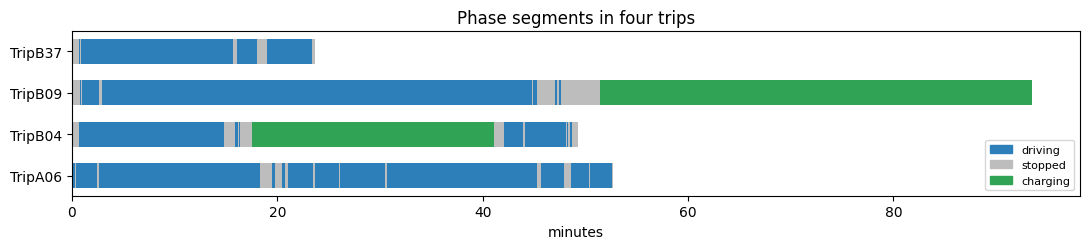

In [5]:
colors = {"driving": "#2c7fb8", "stopped": "#bdbdbd", "charging": "#31a354"}
pick = ["TripA06", "TripB04", "TripB09", "TripB37"]
fig, ax = plt.subplots(figsize=(11, 2.6))
for y, t in enumerate(pick):
    for r in segments[segments.trip_id == t].itertuples():
        ax.barh(y, (r.end_s - r.start_s) / 60, left=r.start_s / 60, color=colors[r.phase], height=0.6)
ax.set_yticks(range(len(pick)), pick)
ax.set_xlabel("minutes")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=list(colors), fontsize=8,
          loc="lower right")
ax.set_title("Phase segments in four trips")
fig.tight_layout()
fig.savefig(FIGURES / "03_phase_segments.png", dpi=150)
plt.show()

## 3 · Voltage-sag events

When the motor draws a large current, the pack voltage dips. Almost all of the dip comes from the pack's
internal resistance (a quick fit gives about 0.08 V per amp). The method:

1. **Relaxed voltage:** the smoothed voltage at moments of low load (|current| < 20 A), carried forward in time.
   It moves slowly with SoC.
2. **Sag** = relaxed voltage − smoothed voltage.
3. **Event:** sag of at least 15 V lasting at least 1 s while driving. Two dips less than 2 s apart count as one event.
4. For each event, the **apparent pack resistance** = sag at the deepest point ÷ (discharge current there −
   current at the relaxed reference). Resistance rises in the cold, so this links the signal to battery health and temperature.

In [6]:
SAG_MIN_V = 15
SAG_MIN_S = 1
GAP_MERGE_S = 2
LOW_LOAD_A = 20


def relaxed(g):
    low = g.current_smooth_a.abs() < LOW_LOAD_A
    v_rel = g.voltage_smooth_v.where(low).ffill().bfill()
    i_rel = g.current_smooth_a.where(low).ffill().bfill()
    return pd.DataFrame({"v_relaxed": v_rel, "i_relaxed": i_rel})


s[["v_relaxed", "i_relaxed"]] = pd.concat([relaxed(g) for _, g in s.groupby("trip_id", sort=False)])
s["sag_v"] = (s.v_relaxed - s.voltage_smooth_v).clip(lower=0)

events = []
for t, g in s.groupby("trip_id", sort=False):
    hot = ((g.sag_v >= SAG_MIN_V) & (g.phase_segmented == "driving")).to_numpy()
    # close gaps shorter than GAP_MERGE_S so one acceleration is one event
    idx = np.flatnonzero(hot)
    if len(idx) == 0:
        continue
    breaks = np.flatnonzero(np.diff(idx) > GAP_MERGE_S * HZ)
    for a, b in zip(np.r_[0, breaks + 1], np.r_[breaks, len(idx) - 1]):
        lo, hi = idx[a], idx[b] + 1
        if (hi - lo) * DT < SAG_MIN_S:
            continue
        part = g.iloc[lo:hi]
        k = part.sag_v.idxmax()
        d_current = part.i_relaxed[k] - part.current_smooth_a[k]  # positive: extra discharge current
        events.append(dict(
            trip_id=t, start_s=part.time_s.iat[0], duration_s=round((hi - lo) * DT, 1),
            max_sag_v=part.sag_v[k], min_voltage_v=part.voltage_smooth_v[k], v_relaxed=part.v_relaxed[k],
            current_at_max_sag_a=part.current_smooth_a[k], speed_kmh=part.speed_kmh[k], soc_pct=part.soc_pct[k],
            batt_temp_c=part.batt_temp_c[k], ambient_temp_c=part.ambient_temp_c[k],
            apparent_resistance_mohm=1000 * part.sag_v[k] / d_current if d_current > 50 else np.nan,
        ))
sag_events = pd.DataFrame(events).merge(trips[["trip_id", "season"]], on="trip_id")
print(f"sag events: {len(sag_events):,} in {sag_events.trip_id.nunique()} trips")
sag_events.groupby("season").agg(events=("trip_id", "size"), median_sag_v=("max_sag_v", "median"),
                                 max_sag_v=("max_sag_v", "max"), median_duration_s=("duration_s", "median"),
                                 median_resistance_mohm=("apparent_resistance_mohm", "median")).round(1)

sag events: 556 in 56 trips


,events,median_sag_v,max_sag_v,median_duration_s,median_resistance_mohm
season,,,,,
summer,78,18.9,30.7,2.6,91.0
winter,478,21.2,51.9,2.8,151.9


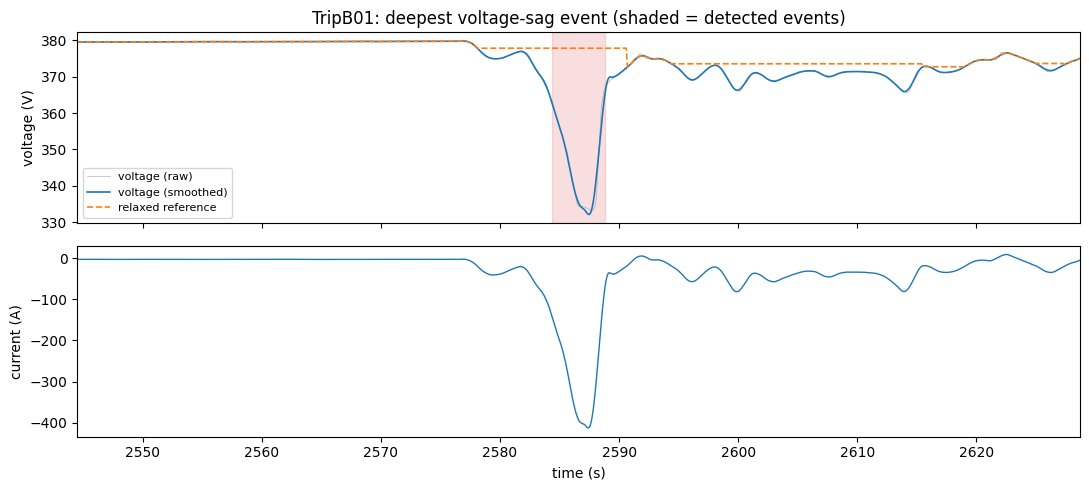

In [7]:
t = "TripB01"
g = s[s.trip_id == t]
ev = sag_events[sag_events.trip_id == t]
k = ev.max_sag_v.idxmax()
w = g[(g.time_s > ev.start_s[k] - 40) & (g.time_s < ev.start_s[k] + ev.duration_s[k] + 40)]
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(w.time_s, w.batt_voltage_v, lw=0.5, color="0.7", label="voltage (raw)")
axes[0].plot(w.time_s, w.voltage_smooth_v, lw=1.2, label="voltage (smoothed)")
axes[0].plot(w.time_s, w.v_relaxed, lw=1.2, ls="--", label="relaxed reference")
for r in ev.itertuples():
    if r.start_s + r.duration_s >= w.time_s.min() and r.start_s <= w.time_s.max():
        axes[0].axvspan(r.start_s, r.start_s + r.duration_s, color="tab:red", alpha=0.15)
axes[0].set_xlim(w.time_s.min(), w.time_s.max())
axes[0].set_ylabel("voltage (V)")
axes[0].legend(fontsize=8)
axes[1].plot(w.time_s, w.current_smooth_a, lw=1)
axes[1].set_ylabel("current (A)")
axes[1].set_xlabel("time (s)")
axes[0].set_title(f"{t}: deepest voltage-sag event (shaded = detected events)")
fig.tight_layout()
fig.savefig(FIGURES / "03_sag_event.png", dpi=150)
plt.show()

## 4 · Battery temperature rise

Battery temperature is logged in whole degrees (notebook 01), so the analysis stays at trip level:
start, end, peak, the rise, and the rise rate per hour of driving. Each one-degree step up is also counted,
with the time to the first step.

In [8]:
rows = []
for t, g in s.groupby("trip_id", sort=False):
    temp = g.batt_temp_c
    steps_up = (temp.diff() >= 1).sum()
    first_up = g.time_s[temp > temp.iat[0]]
    driving_h = (g.phase_segmented == "driving").sum() * DT / 3600
    rows.append(dict(trip_id=t, batt_temp_start_c=temp.iat[0], batt_temp_end_c=temp.iat[-1], batt_temp_max_c=temp.max(),
                     rise_c=temp.max() - temp.iat[0], driving_h=round(driving_h, 3),
                     rise_rate_c_per_h=(temp.max() - temp.iat[0]) / driving_h if driving_h > 0 else np.nan,
                     steps_up=int(steps_up), first_step_min=first_up.iat[0] / 60 if len(first_up) else np.nan,
                     ambient_mean_c=g.ambient_temp_c.mean()))
temp_rise = pd.DataFrame(rows).merge(trips[["trip_id", "season"]], on="trip_id")
temp_rise.groupby("season")[["batt_temp_start_c", "rise_c", "rise_rate_c_per_h", "ambient_mean_c"]].median().round(1)

,batt_temp_start_c,rise_c,rise_rate_c_per_h,ambient_mean_c
season,,,,
summer,20.5,1.0,3.9,22.3
winter,9.0,3.0,8.9,5.1


## 5 · Per-trip energy

Power is integrated over time (Δt = 0.1 s):

| Quantity | Definition |
|---|---|
| `energy_out_kwh` | energy drawn from the battery (negative power), all phases |
| `energy_regen_kwh` | energy returned while driving (positive power during driving) |
| `energy_charged_kwh` | energy put in while charging |
| `energy_net_drive_kwh` | out − regen, excluding charging |
| `heating_kwh`, `aircon_kwh` | integrated heating (CAN signal) and air-conditioning power |
| `distance_km` | integrated speed |

Two cross-checks keep the integration honest: integrated distance against the overview sheet, and battery
energy against the SoC drop.

In [9]:
s["discharge_kw"] = (-s.power_kw).clip(lower=0)
s["recharge_kw"] = s.power_kw.clip(lower=0)
drive = s.phase_segmented == "driving"
charge = s.phase_segmented == "charging"
agg = pd.DataFrame({
    "energy_out_kwh": s.discharge_kw.groupby(s.trip_id).sum() * DT / 3600,
    "energy_regen_kwh": s.recharge_kw.where(drive, 0).groupby(s.trip_id).sum() * DT / 3600,
    "energy_charged_kwh": s.recharge_kw.where(charge, 0).groupby(s.trip_id).sum() * DT / 3600,
    "heating_kwh": s.heating_power_can_kw.fillna(0).groupby(s.trip_id).sum() * DT / 3600,
    "aircon_kwh": s.aircon_power_kw.fillna(0).groupby(s.trip_id).sum() * DT / 3600,
    "distance_km_integrated": s.speed_kmh.fillna(0).groupby(s.trip_id).sum() * DT / 3600,
    "driving_h": drive.groupby(s.trip_id).sum() * DT / 3600,
})
agg["energy_net_drive_kwh"] = agg.energy_out_kwh - agg.energy_regen_kwh - s.discharge_kw.where(charge, 0).groupby(s.trip_id).sum() * DT / 3600
agg["regen_share_pct"] = 100 * agg.energy_regen_kwh / agg.energy_out_kwh
agg["heating_share_pct"] = 100 * agg.heating_kwh / agg.energy_out_kwh

# SoC change, only for trips with a complete SoC and no charging
soc_ok = s.groupby("trip_id").agg(soc_first=("soc_pct", "first"), soc_last=("soc_pct", "last"),
                                  any_gap=("soc_gap", "any"))
agg = agg.join(soc_ok)
agg["soc_used_pct"] = agg.soc_first - agg.soc_last
trip_energy = trips[["trip_id", "season", "distance_km", "ambient_temp_start_c"]].merge(
    agg.reset_index(), on="trip_id")
trip_energy["consumption_kwh_per_100km"] = 100 * trip_energy.energy_net_drive_kwh / trip_energy.distance_km_integrated
trip_energy.groupby("season")[["distance_km_integrated", "energy_net_drive_kwh", "consumption_kwh_per_100km",
                               "regen_share_pct", "heating_share_pct"]].median().round(1)

,distance_km_integrated,energy_net_drive_kwh,consumption_kwh_per_100km,regen_share_pct,heating_share_pct
season,,,,,
summer,16.1,2.0,13.3,23.1,0.0
winter,16.7,3.3,19.1,11.6,18.0


distance: integrated vs overview, median error +0.0 %, worst 38.5 % (TripA30)
trips off by more than 3 %: ['TripA30']
overview rows for A30/A31 (same start time in notebook 01):
trip_id          start_time  distance_km  soc_start_frac  soc_end_frac
TripA30 2019-07-19 09:34:23     7.746444           0.855         0.810
TripA31 2019-07-19 09:34:23    15.976052           0.810         0.825
         first  last
trip_id             
TripA30   85.5  81.0
TripA31   81.0  71.9
battery energy vs SoC used (64 trips): 0.220 kWh per SoC point, i.e. about 22.0 kWh for 100 %, correlation 0.997


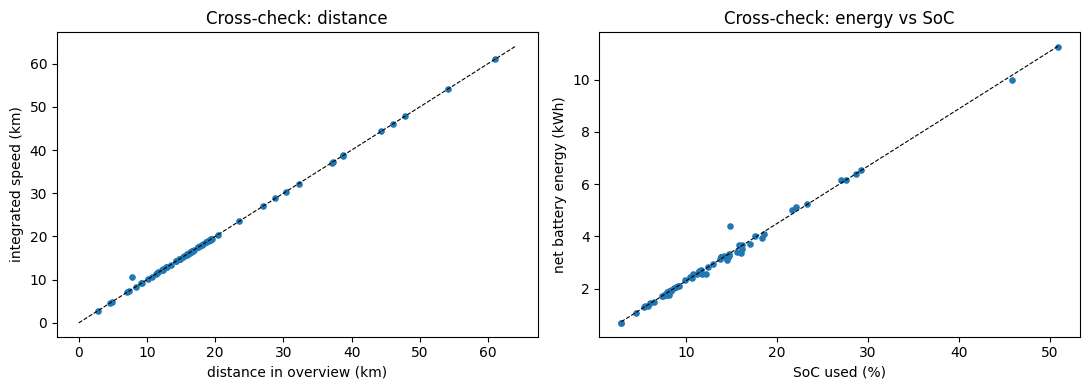

In [10]:
# cross-check 1: integrated distance vs the overview sheet
dist_err = 100 * (trip_energy.distance_km_integrated / trip_energy.distance_km - 1)
print(f"distance: integrated vs overview, median error {dist_err.median():+.1f} %, "
      f"worst {dist_err.abs().max():.1f} % ({trip_energy.trip_id[dist_err.abs().idxmax()]})")
print("trips off by more than 3 %:", trip_energy.trip_id[dist_err.abs() > 3].tolist())
print("overview rows for A30/A31 (same start time in notebook 01):")
print(trips.loc[trips.trip_id.isin(["TripA30", "TripA31"]),
                ["trip_id", "start_time", "distance_km", "soc_start_frac", "soc_end_frac"]].to_string(index=False))
print(s[s.trip_id.isin(["TripA30", "TripA31"])].groupby("trip_id").soc_pct.agg(["first", "last"]).to_string())

# cross-check 2: net battery energy vs SoC used (trips with complete SoC and no charging)
ok = (~trip_energy.any_gap) & (trip_energy.energy_charged_kwh == 0) & (trip_energy.soc_used_pct > 2)
fit = np.polyfit(trip_energy.soc_used_pct[ok], trip_energy.energy_out_kwh[ok] - trip_energy.energy_regen_kwh[ok], 1)
r = np.corrcoef(trip_energy.soc_used_pct[ok], trip_energy.energy_out_kwh[ok] - trip_energy.energy_regen_kwh[ok])[0, 1]
print(f"battery energy vs SoC used ({ok.sum()} trips): {fit[0]:.3f} kWh per SoC point, "
      f"i.e. about {fit[0] * 100:.1f} kWh for 100 %, correlation {r:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(trip_energy.distance_km, trip_energy.distance_km_integrated, s=14)
lim = [0, trip_energy.distance_km.max() * 1.05]
axes[0].plot(lim, lim, "k--", lw=0.8)
axes[0].set_xlabel("distance in overview (km)")
axes[0].set_ylabel("integrated speed (km)")
axes[0].set_title("Cross-check: distance")
x = trip_energy.soc_used_pct[ok]
axes[1].scatter(x, trip_energy.energy_out_kwh[ok] - trip_energy.energy_regen_kwh[ok], s=14)
axes[1].plot(x.sort_values(), np.polyval(fit, x.sort_values()), "k--", lw=0.8)
axes[1].set_xlabel("SoC used (%)")
axes[1].set_ylabel("net battery energy (kWh)")
axes[1].set_title("Cross-check: energy vs SoC")
fig.tight_layout()
fig.savefig(FIGURES / "03_energy_checks.png", dpi=150)
plt.show()

**Reading the cross-checks**
- Integrated distance matches the overview for every trip except **TripA30**. The overview rows for A30 and A31 also
  share a start time, and A31's end SoC in the overview contradicts its own file, so those two overview rows look
  partly copy-pasted. **The values integrated from the signals are used from here on;** the overview figures
  stay for reference only.
- Net battery energy follows SoC used almost perfectly. The slope implies a full battery of roughly 22 kWh,
  in line with the rated energy of the BMW i3 60 Ah pack (about 21.6 kWh). The power integration can be trusted.

## 6 · Save to DuckDB

In [11]:
samples = s[["trip_id", "row_idx", "time_s", "phase_segmented", "segment_no", "voltage_smooth_v", "current_smooth_a",
             "power_kw", "power_smooth_kw", "v_relaxed", "sag_v"]].rename(columns={"phase_segmented": "phase"})
con.execute("DROP SCHEMA IF EXISTS signal CASCADE")
con.execute("CREATE SCHEMA signal")
for table, frame in {"signal.samples": samples, "signal.segments": segments, "signal.sag_events": sag_events,
                     "signal.temp_rise": temp_rise, "signal.trip_energy": trip_energy,
                     "signal.smoothing_comparison": comparison}.items():
    con.register("frame_view", frame)
    con.execute(f"CREATE TABLE {table} AS SELECT * FROM frame_view")
    con.unregister("frame_view")
for name, frame in {"03_segments": segments, "03_sag_events": sag_events, "03_temp_rise": temp_rise,
                    "03_trip_energy": trip_energy}.items():
    frame.to_csv(REPORTS / f"{name}.csv", index=False)
con.sql("SELECT table_name, estimated_size AS rows, column_count FROM duckdb_tables() WHERE schema_name = 'signal'").df()

,table_name,rows,column_count
0,sag_events,556,13
1,samples,1094793,11
2,segments,1193,9
3,smoothing_comparison,6,4
4,temp_rise,70,11
5,trip_energy,70,19


## 7 · Checks

In [12]:
def q(sql):
    return con.execute(sql).fetchone()[0]


checks = {
    "one smoothed row per clean sample":
        "SELECT abs((SELECT count(*) FROM signal.samples) - (SELECT count(*) FROM clean.trip_signals))",
    "segments cover every sample exactly once":
        "SELECT abs((SELECT round(sum(duration_s) * 10) FROM signal.segments) - (SELECT count(*) FROM clean.trip_signals))",
    "segments in a trip do not overlap":
        "SELECT count(*) FROM (SELECT start_s, lag(end_s) OVER (PARTITION BY trip_id ORDER BY segment_no) AS prev_end "
        "FROM signal.segments) WHERE start_s < prev_end - 1e-6",
    "every sag event lies inside a driving segment":
        "SELECT count(*) FROM signal.sag_events e WHERE NOT EXISTS (SELECT 1 FROM signal.segments g WHERE g.trip_id = e.trip_id "
        "AND g.phase = 'driving' AND e.start_s >= g.start_s - 1e-6 AND e.start_s < g.end_s)",
    "energy table has every trip":
        "SELECT 70 - count(*) FROM signal.trip_energy",
    "no negative energies":
        "SELECT count(*) FROM signal.trip_energy WHERE energy_out_kwh < 0 OR energy_regen_kwh < 0 OR energy_charged_kwh < 0",
}
results = pd.DataFrame([{"check": k, "failures": q(v)} for k, v in checks.items()])
results["passed"] = results.failures == 0
print(results.to_string(index=False))
assert results.passed.all()
con.close()

                                        check  failures  passed
            one smoothed row per clean sample       0.0    True
     segments cover every sample exactly once       0.0    True
            segments in a trip do not overlap       0.0    True
every sag event lies inside a driving segment       0.0    True
                  energy table has every trip       0.0    True
                         no negative energies       0.0    True


## 8 · Summary

- **Smoothing:** Savitzky-Golay over 2 s keeps the depth of current and power peaks, while a moving average
  flattens them. Savitzky-Golay is therefore used for `voltage_smooth_v`, `current_smooth_a` and `power_smooth_kw`.
- **Segments:** 1,193 continuous phases (566 driving, 625 stopped, 2 charging). The 2 s merge relabelled only 0.2 % of samples.
- **Voltage sag:** 556 heavy-load events. Winter events are deeper, and the apparent pack resistance is clearly
  higher in the cold, which is a physical effect, not noise.
- **Temperature rise:** winter trips start colder and warm up faster per hour of driving than summer trips.
- **Energy:** per-trip energy used, recovered, charged and spent on heating, plus consumption per 100 km. Two independent
  checks confirm the integration: distance matches the overview, and battery energy tracks SoC used.
  The one mismatch (TripA30) is an error in the overview sheet.

Interpreting these patterns is the job of the next step, EDA.